# Đồ Án Machine Learning: Phân Loại Biển Báo Giao Thông
## Notebook 01: Khám Phá & Phân Tích Dữ Liệu (Exploratory Data Analysis - EDA)

Notebook này thực hiện thống kê, phân tích và trực quan hóa tập dữ liệu toàn diện 268 lớp biển báo giao thông và ngoại cảnh Việt Nam.

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Đã import các thư viện phân tích dữ liệu.')

Đã import các thư viện phân tích dữ liệu.


### 1. Đọc và kiểm tra thông tin tập dữ liệu

In [23]:
summary_path = Path('../data/processed/dataset_summary.csv')
df = pd.read_csv(summary_path)
print(f'Tổng số mẫu biển báo: {len(df)}')
print(f'Số lượng cột: {list(df.columns)}')
df.head()

Tổng số mẫu biển báo: 6500
Số lượng cột: ['crop_rel_path', 'split', 'class_id', 'sign_code', 'sign_name_vi', 'category']


,crop_rel_path,split,class_id,sign_code,sign_name_vi,category
0,processed\train\0\0_train_0.jpg,train,0,P.101,Đường cấm,Biển cấm
1,processed\train\0\0_train_1.jpg,train,0,P.101,Đường cấm,Biển cấm
2,processed\train\0\0_train_2.jpg,train,0,P.101,Đường cấm,Biển cấm
3,processed\train\0\0_train_3.jpg,train,0,P.101,Đường cấm,Biển cấm
4,processed\train\0\0_train_4.jpg,train,0,P.101,Đường cấm,Biển cấm


### 2. Phân bố dữ liệu giữa các tập Train - Val - Test

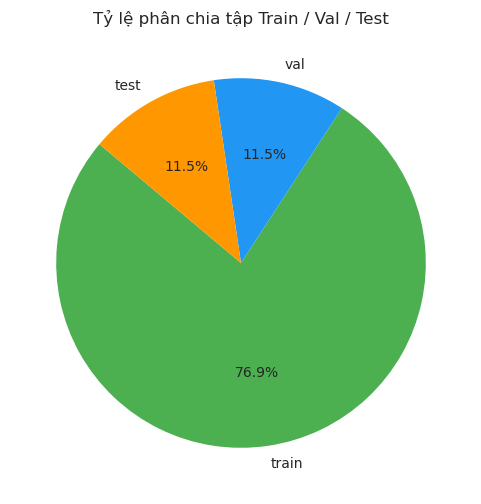

split
train    5000
val       750
test      750
Name: count, dtype: int64


In [24]:
split_counts = df['split'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(split_counts, labels=split_counts.index, autopct='%1.1f%%', colors=['#4CAF50', '#2196F3', '#FF9800'], startangle=140)
plt.title('Tỷ lệ phân chia tập Train / Val / Test')
plt.show()
print(split_counts)

### 3. Phân bố số lượng mẫu theo từng loại biển báo (Top 15 lớp phổ biến nhất)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_10644\2949556849.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15.values, y=top15.index, palette='Blues_r')


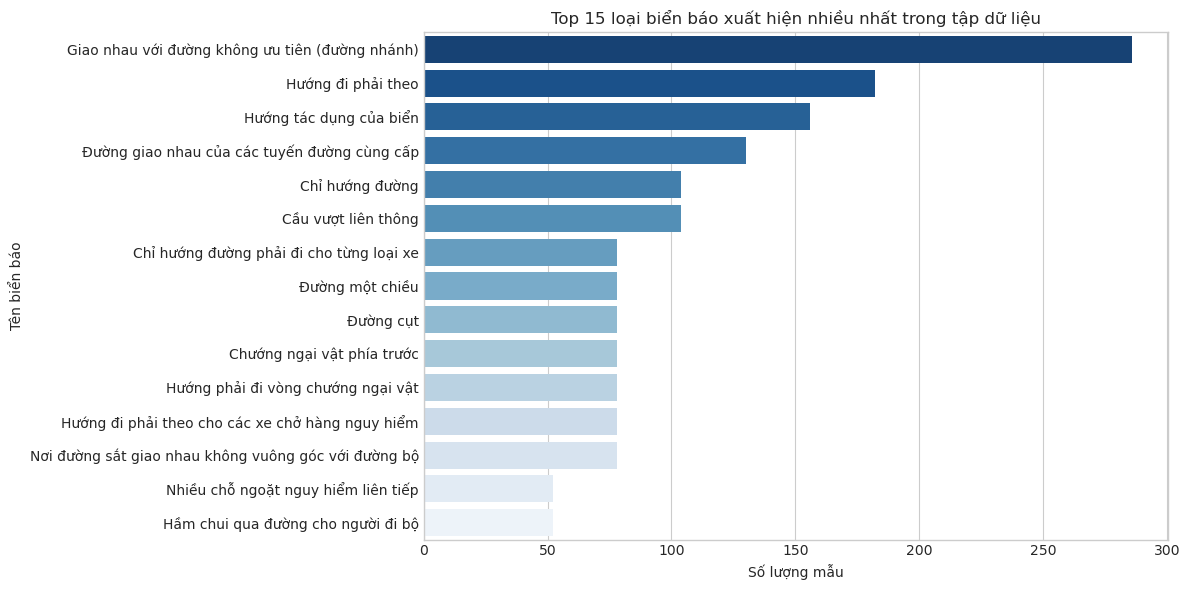

In [25]:
top15 = df['sign_name_vi'].value_counts().head(15)
plt.figure(figsize=(12, 6))
sns.barplot(x=top15.values, y=top15.index, palette='Blues_r')
plt.title('Top 15 loại biển báo xuất hiện nhiều nhất trong tập dữ liệu')
plt.xlabel('Số lượng mẫu')
plt.ylabel('Tên biển báo')
plt.tight_layout()
plt.show()

### 4. Phân bố kích thước ảnh biển báo (Crop Width & Height)

KeyError: 'crop_w'

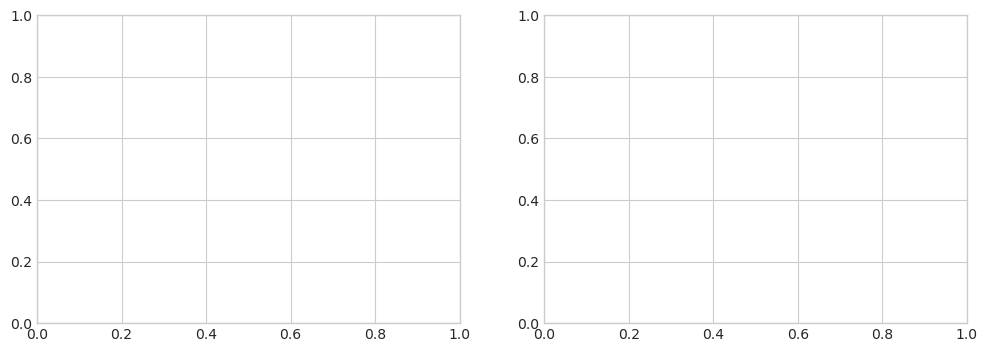

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['crop_w'], bins=30, ax=axes[0], color='purple', kde=True)
axes[0].set_title('Phân bố Chiều rộng (Width) của biển báo')
sns.histplot(df['crop_h'], bins=30, ax=axes[1], color='teal', kde=True)
axes[1].set_title('Phân bố Chiều cao (Height) của biển báo')
plt.tight_layout()
plt.show()

### 5. Hiển thị một số mẫu ảnh thực tế

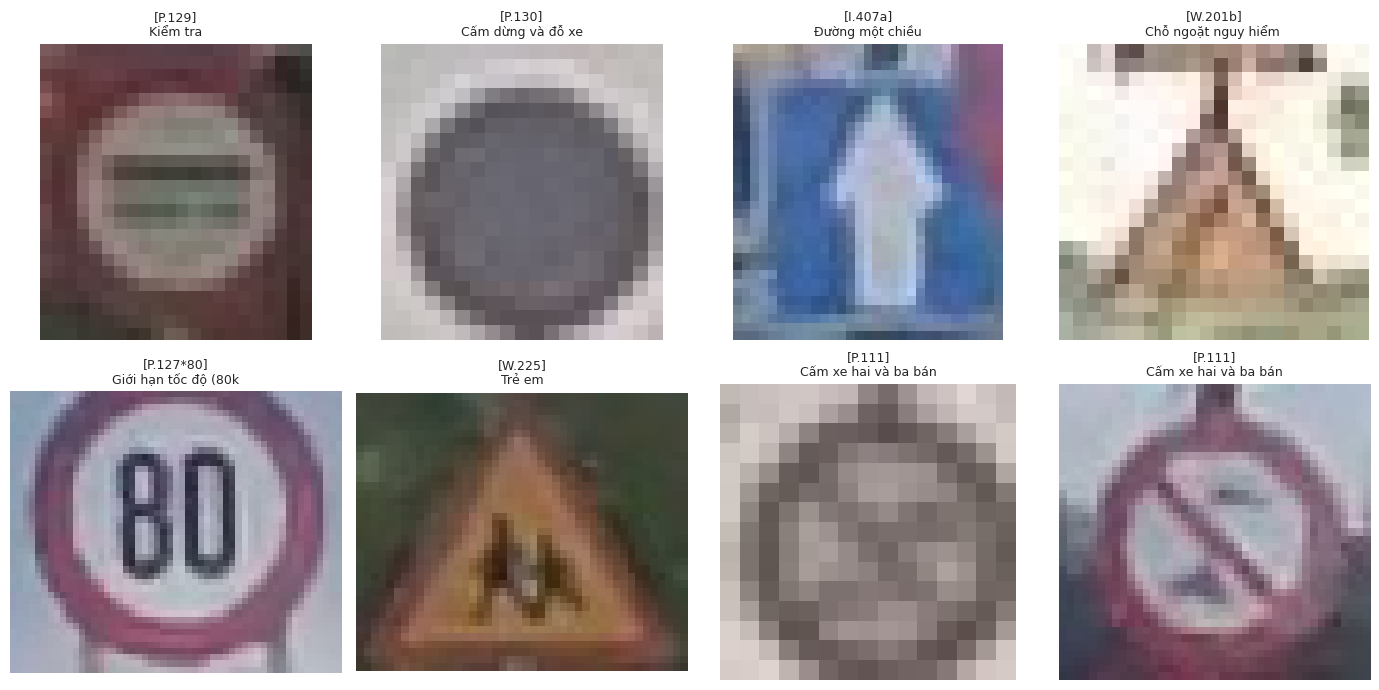

In [ ]:
sample_df = df.sample(8, random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes.flatten(), sample_df.iterrows()):
    img_path = Path('../data') / row['crop_rel_path']
    if img_path.exists():
        im = Image.open(img_path)
        ax.imshow(im)
    ax.set_title(f"[{row['sign_code']}]\n{row['sign_name_vi'][:20]}", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()